# Retail demand forecasting → inventory and capacity decisions (walkthrough)

This notebook walks through how the forecasting models were built and validated, and what they are worth for the decision each one supports. The data checks, cleaning and feature engineering run live; model results are read from `results/`, produced by the pipelines in `src/retail_demand/`.

| Part | Data | Decision |
|---|---|---|
| A | TCS iON: 50 products × 10 outlets, daily, 2012-2014, weekly prices | how much to order each week per product and outlet (intermittent demand) |
| B | Favorita (Ecuador): 54 stores × 33 product families, daily, 2013-2017 | how much to stock per store and family for the next order cycle |
| C | Hourly demand, Aug 2018 - Feb 2021 | how much capacity to plan for each hour next week |

In [1]:
import json, subprocess, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = Path("..") if (Path("..") / "src" / "retail_demand").exists() else Path("retail-demand-optimization")
if not (ROOT / "src").exists():                     # opened on its own (e.g. in Colab): fetch the repository
    subprocess.run(["git", "clone", "-q", "https://github.com/Muneera-DSA/retail-demand-optimization.git"], check=True)
sys.path.insert(0, str(ROOT / "src"))
from retail_demand import config
from retail_demand.hourly import data as hdata, features as hfeat, quality as hq
FIG, RES = ROOT / "reports" / "figures", ROOT / "results"
load = lambda part, name: json.loads((RES / part / f"{name}.json").read_text())
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)

## Part B: Favorita → replenishment for 1,782 store × family series

The Kaggle files are not redistributed. If `data/favorita/` holds them, the next cells run the checks live; otherwise they show the saved results.

In [2]:
fav_dir = ROOT / "data" / "favorita"
live = all((fav_dir / f"{f}.csv").exists() for f in ("train", "stores", "oil", "holidays_events", "transactions", "test"))
if live:
    from retail_demand.favorita import data as fdata
    d = fdata.load(fav_dir); p = fdata.build_panel(d); q = fdata.quality(d, p)
    print(f"panel: {p.sales.shape[0]:,} series x {p.sales.shape[1]:,} days (live)")
else:
    q = load("favorita", "quality"); print("data not present: showing saved checks")
for k in ("validity", "uniqueness", "completeness", "consistency"):
    print(f"\n{k.upper()}"); print(json.dumps({a: b for a, b in q[k].items() if not isinstance(b, (list, dict)) or len(str(b)) < 160}, indent=1, default=str))

panel: 1,782 series x 1,704 days (live)

VALIDITY
{
 "train_rows": 3000888,
 "test_rows": 28512,
 "negative_sales": 0,
 "negative_promotions": 0,
 "fractional_sales_share": 0.15399208500950384,
 "fractional_sales_families": [
  "BREAD/BAKERY",
  "DELI",
  "FROZEN FOODS",
  "GROCERY I",
  "MEATS",
  "POULTRY",
  "PREPARED FOODS",
  "PRODUCE",
  "SEAFOOD"
 ],
 "null_values": {
  "train": 0,
  "stores": 0,
  "oil": 43,
  "holidays_events": 0,
  "transactions": 0,
  "test": 0
 },
 "store_numbers_not_in_stores_file": 0
}

UNIQUENESS
{
 "duplicate_store_family_date": 0,
 "duplicate_transactions": 0,
 "duplicate_holiday_date_place": 7
}

COMPLETENESS
{
 "first_date": "2013-01-01",
 "last_date": "2017-08-15",
 "series": 1782,
 "expected_series": 1782,
 "dates_absent_from_file": [
  "2013-12-25",
  "2014-12-25",
  "2015-12-25",
  "2016-12-25"
 ],
 "stores_opening_after_start": {
  "20": "2015-02-13",
  "21": "2015-07-24",
  "22": "2015-10-09",
  "29": "2015-03-20",
  "36": "2013-05-09",
  "42":

**Cleaning decisions:** days before a store opened are not demand and are masked; 25 December (stores closed) stays unobserved; series that sold nothing in the last 56 days are forecast as zero; promotions only exist from April 2014, so training starts in 2015. Outliers (e.g. earthquake relief buying in April-May 2016) are kept; the model is trained on log1p(sales).

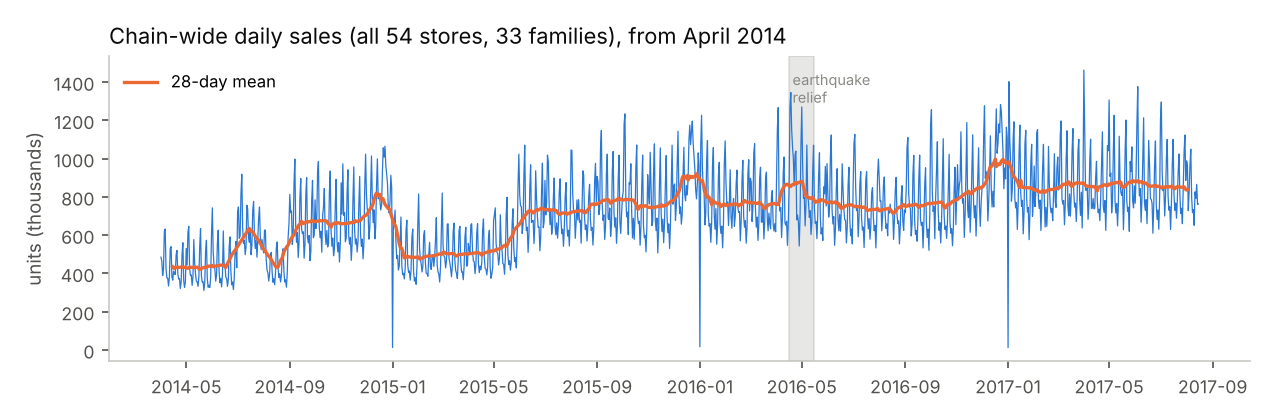

share of unit sales, top families: {'GROCERY I': '31%', 'BEVERAGES': '21%', 'PRODUCE': '13%', 'CLEANING': '9%', 'DAIRY': '6%'}
promotion days sell 1.30x other days within a series (98% of 1222 series) - association, not causal


In [3]:
eda = load("favorita", "eda")
display(Image(filename=str(FIG / "favorita_daily.png"), width=760))
print("share of unit sales, top families:", {k: f"{v:.0%}" for k, v in list(eda["share_of_sales_top_families"].items())[:5]})
pl = eda["promotion_lift_within_series"]
print(f"promotion days sell {pl['median_ratio']:.2f}x other days within a series ({pl['share_positive']:.0%} of {pl['series']} series) - association, not causal")

**Features** (computed at each order date, for each of the next 16 days): recent sales levels (7-112 days), same-weekday history, volatility, zero share, days since last sale, store transactions, oil price at the order date; and, for the target day, planned promotions, holidays (national / regional / local, transfers, work days), payday, calendar. A test in `tests/test_favorita.py` alters everything after the order date and checks that no feature changes.

,model,baseline,wape,rmsle,bias
0,Random forest (log scale),False,0.126,0.394,-0.020
1,Extra trees (log scale),False,0.129,0.390,-0.024
2,"Neural network (MLP 128-64, log scale)",False,0.130,0.404,0.002
3,"Gradient boosting (log scale, squared error)",False,0.133,0.390,-0.040
4,"Same-weekday mean, last 4 weeks",True,0.143,0.452,0.014
5,Ridge (log scale),False,0.158,0.404,0.004
6,"Seasonal naive (same weekday, last week)",True,0.162,0.523,-0.021
7,"Gradient boosting (Poisson, units)",False,0.184,0.422,-0.144
8,Mean of the last 14 days,True,0.244,0.475,0.007


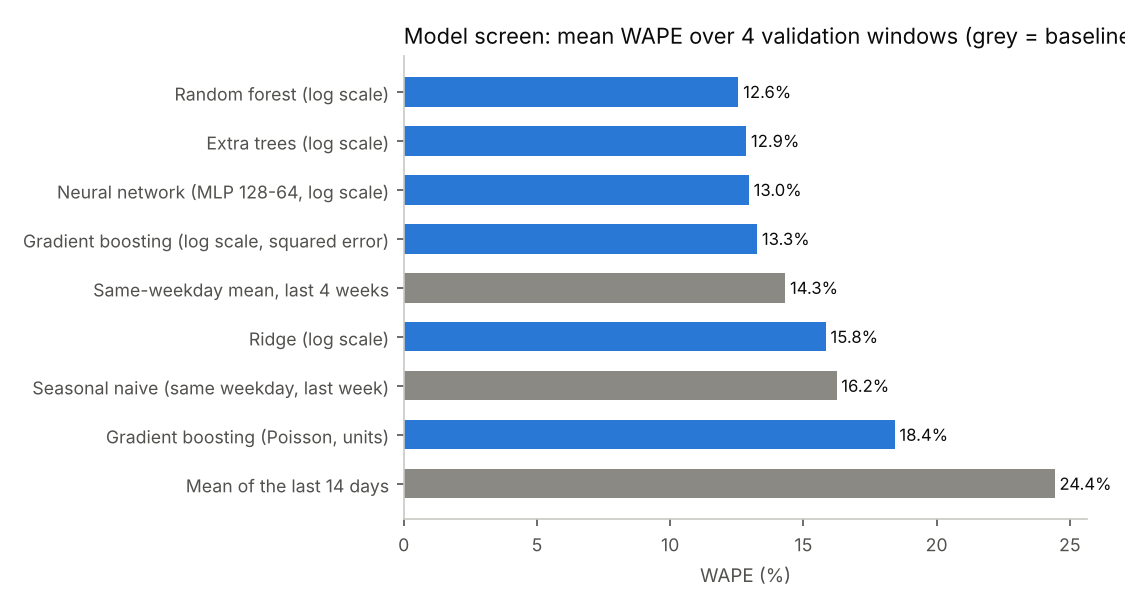

In [4]:
sc = load("favorita", "screen")
display(pd.DataFrame(sc["table"])[["model", "baseline", "wape", "rmsle", "bias"]].round(3))
display(Image(filename=str(FIG / "favorita_screen.png"), width=640))

In [5]:
t = load("favorita", "test")
display(pd.DataFrame(t["table"]).T[["wape", "rmsle", "bias"]].astype(float).round(3))
pr = pd.read_csv(RES / "favorita" / "test_predictions.csv.gz")
by_day = pr.groupby("date").apply(lambda d: pd.Series({m: (d[m] - d.y).sum() / d.y.sum() for m in ("Random forest (log scale)", "Ridge (log scale)")}), include_groups=False)
display((by_day * 100).round(1).rename(columns=lambda c: c + ": bias %"))

,wape,rmsle,bias
Random forest (log scale),0.163,0.447,0.020
"Seasonal naive (same weekday, last week)",0.207,0.617,0.004
"Same-weekday mean, last 4 weeks",0.176,0.531,0.006
Mean of the last 14 days,0.208,0.519,0.001
Ridge (log scale),0.161,0.492,-0.033


,Random forest (log scale): bias %,Ridge (log scale): bias %
date,,
2017-07-31,-11.0,-11.5
2017-08-01,-16.9,-25.9
2017-08-02,-7.6,-15.1
2017-08-03,4.4,-7.2
2017-08-04,6.3,-1.3
2017-08-05,8.4,-2.7
2017-08-06,6.2,-4.2
2017-08-07,-0.6,-7.6
2017-08-08,1.8,-0.3


The test window contains a national holiday moved to Friday 11 August (a long weekend). The random forest over-forecasts that Saturday and Sunday by about 22%; the validation windows (May-July) had no such event, which is why its validation lead over Ridge did not carry over.

7-day cycle


,forecast_wape_of_totals,cycle_service_level,fill_rate,stock_saving_vs_rule_at_99pct_fill
Random forest (log scale) (final model),0.088,0.935,0.987,-0.068
Ridge (log scale),0.114,0.910,0.982,0.001
"Same-weekday mean, last 4 weeks",0.098,0.901,0.982,-0.000
Rule of thumb: 28-day average,0.098,0.901,0.982,0.000


16-day cycle


,forecast_wape_of_totals,cycle_service_level,fill_rate,stock_saving_vs_rule_at_99pct_fill
Random forest (log scale) (final model),0.096,0.926,0.993,-0.022
Ridge (log scale),0.080,0.927,0.990,-0.004
"Same-weekday mean, last 4 weeks",0.089,0.915,0.989,-0.003
Rule of thumb: 28-day average,0.093,0.925,0.991,0.000


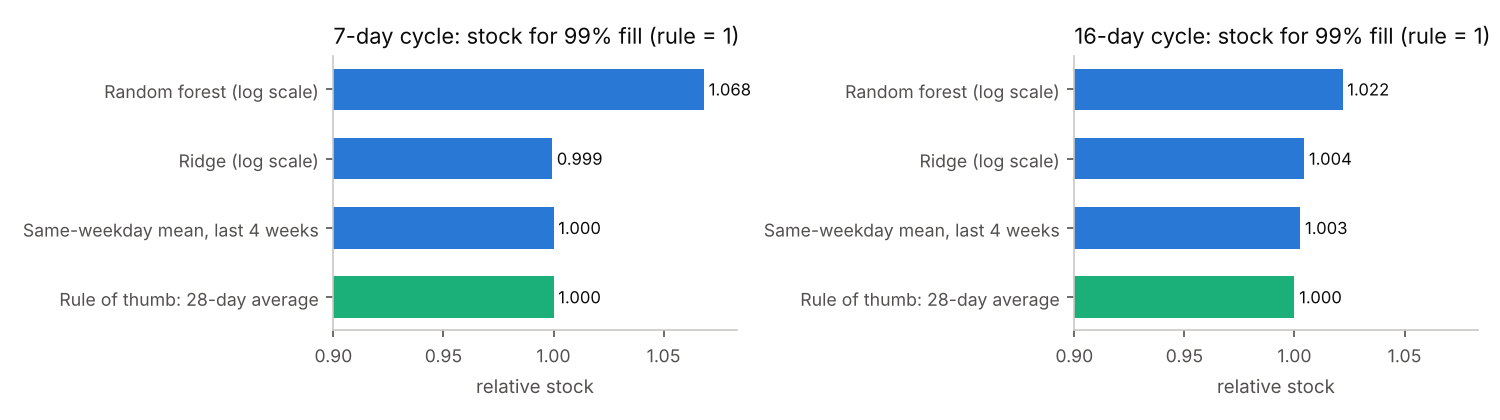

In [6]:
dec = load("favorita", "decision")
for cyc, res in dec["cycles"].items():
    df = pd.DataFrame(res).T[["forecast_wape_of_totals", "cycle_service_level", "fill_rate", "stock_saving_vs_rule_at_99pct_fill"]]
    print(cyc); display(df.astype(float).round(3))
display(Image(filename=str(FIG / "favorita_decision.png"), width=760))

**Better daily accuracy did not reduce the stock needed for the same fill rate.** Stock at high service depends on the worst under-forecasts of large series, and the log-scale models shrink extreme days. Forecast accuracy and inventory value are different targets, so the forecast for a stock decision should be chosen on the decision's own metric.

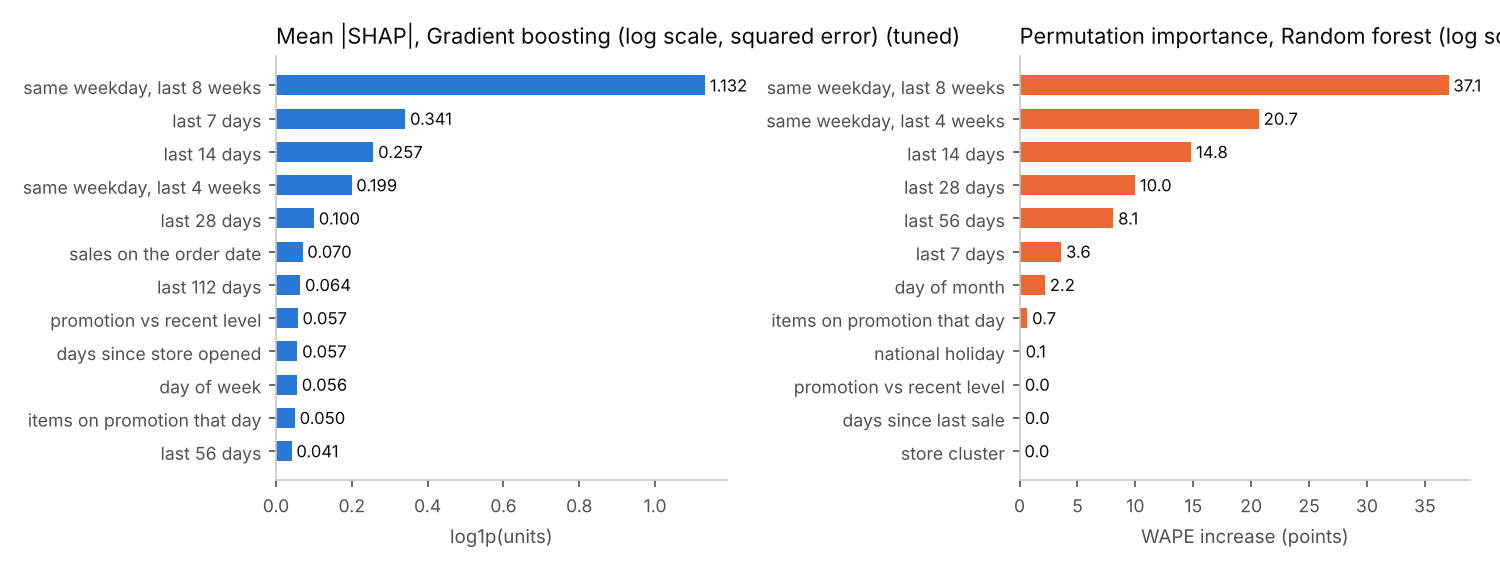

In [7]:
display(Image(filename=str(FIG / "favorita_importance.png"), width=860))

## Part C: hourly demand → week-ahead capacity plan

### C1. Load and validate the raw file (live)

In [8]:
raw = hdata.load_raw(ROOT / "data" / "hourly" / "hourly_demand.csv")
print(raw.shape); display(raw.head(3))
checks = {
    "unparseable dates": int(pd.to_datetime(raw.date, errors="coerce").isna().sum()),
    "hours outside 0-23": int((~raw.hour.between(0, 23)).sum()),
    "non-integer demand": int((raw.demand != raw.demand.round()).sum()),
    "negative demand": int((raw.demand < 0).sum()),
    "zero demand": int((raw.demand == 0).sum()),
    "duplicate date-hours": int(raw.duplicated(["date", "hour"]).sum()),
}
display(pd.Series(checks, name="count").to_frame())

(18247, 3)


,date,hour,demand
0,2018-08-18,9,91
1,2018-08-18,10,21
2,2018-08-18,13,23


,count
unparseable dates,0
hours outside 0-23,0
non-integer demand,0
negative demand,0
zero demand,0
duplicate date-hours,0


The file is clean at row level, but it contains **no zeros at all**, which is suspicious for hourly counts. The next check puts it on a full hourly grid to see which hours are absent.

22,224 hours on the grid, 82.1% recorded
status
observed    18247
gap          3257
outage        720
whole days missing: ['2019-04-28', '2020-11-27', '2020-12-26'] ... (31 days)


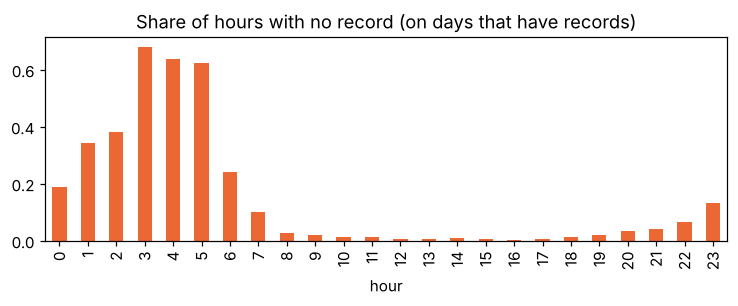

In [9]:
grid = hdata.to_grid(raw)
print(f"{len(grid):,} hours on the grid, {(grid.status == 'observed').mean():.1%} recorded")
print(grid.status.value_counts().to_string())
days = grid.drop_duplicates("date")
miss = days[days.day_missing]
print("whole days missing:", miss.date.dt.strftime("%Y-%m-%d").iloc[[0, 1, -1]].tolist(), f"... ({len(miss)} days)")
on = grid[~grid.day_missing]
share = on.groupby("hour").demand.apply(lambda s: s.isna().mean())
ax = share.plot.bar(figsize=(8, 2.4), color="#eb6834", title="Share of hours with no record (on days that have records)")
plt.show()

In [10]:
q = hq.missingness(grid)
print(f"afternoon demand on days with a missing night hour: {q['peak_mean_days_with_night_gap']:.0f}")
print(f"afternoon demand on other days:                     {q['peak_mean_days_without']:.0f}")
print(f"Mann-Whitney p = {q['mannwhitney_p']:.1g}, Cliff's delta = {q['cliffs_delta']:+.2f}")

afternoon demand on days with a missing night hour: 91
afternoon demand on other days:                     126
Mann-Whitney p = 3e-06, Cliff's delta = -0.39


**Cleaning decisions, each tested:**
- The 30-day block (27 Nov – 26 Dec 2020) is a **recording outage**: a month of zero demand in peak season is not credible. It is excluded.
- The other missing hours are **not random**: they fall on quieter days, mostly at night. They are most likely hours with no activity. Models are fitted on recorded hours, and a sensitivity analysis treats them as zero (conclusions unchanged; see the results).
- 29 values more than 5 robust SDs from their hour-of-week median are kept: nothing marks them as errors.

### C2. Exploratory analysis

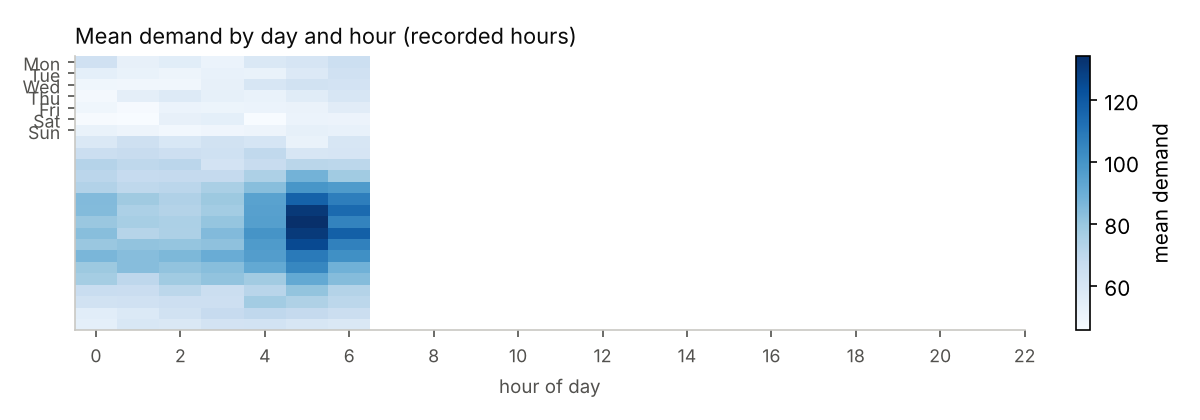

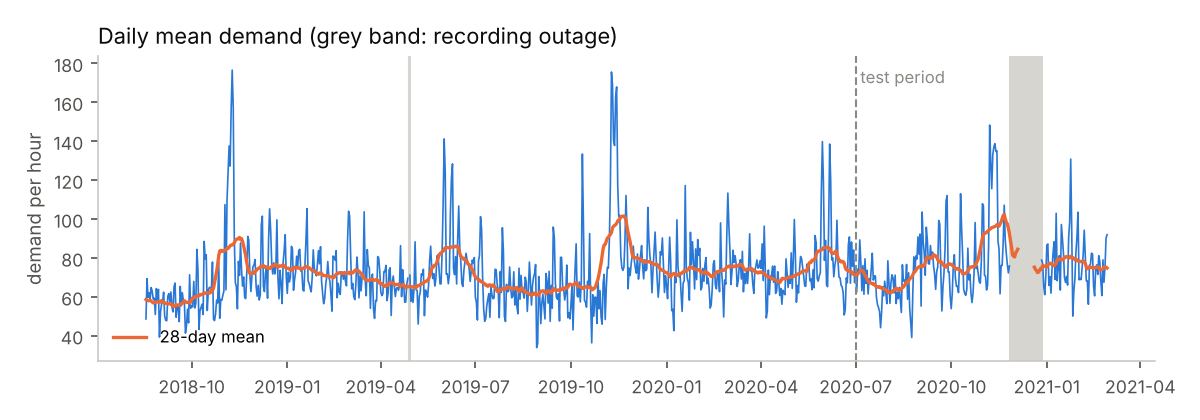

hour of week explains 20% of hourly variance
autocorrelation, hourly: {'1': 0.47, '2': 0.4, '3': 0.35, '24': 0.39, '48': 0.27, '168': 0.27, '336': 0.22}
weekend / weekday daily mean: 1.19


In [11]:
display(Image(filename=str(FIG / "hourly_heatmap.png"), width=760))
display(Image(filename=str(FIG / "hourly_daily.png"), width=760))
eda = load("hourly", "eda")
print(f"hour of week explains {eda['share_of_variance_explained_by_hour_of_week']:.0%} of hourly variance")
print("autocorrelation, hourly:", {k: round(v, 2) for k, v in eda['autocorrelation_hourly'].items()})
print(f"weekend / weekday daily mean: {eda['weekend_vs_weekday']['ratio']:.2f}")

Demand has a strong weekly shape and yearly November peaks, but hour-to-hour noise is large: consecutive hours correlate only at 0.47. That caps how accurate any hourly forecast can be.

### C3. Feature engineering under the week-ahead rule (live)

A staffing plan for next week is drawn up at the start of the week, so a feature for hour *t* may only use data up to *t − 168 h*. The test below changes the last 167 hours before *t* and checks that none of *t*'s features move.

In [12]:
F = hfeat.build(grid)
display(F.loc[24 * 400, hfeat.FEATURES].to_frame("hour 9,600"))
t = 24 * 400
g2 = grid.copy(); g2.loc[t - 167:, "demand"] = g2.loc[t - 167:, "demand"] * 10
same = F.loc[t, hfeat.FEATURES].equals(hfeat.build(g2).loc[t, hfeat.FEATURES])
print("features unchanged when the last week (and the future) is altered:", same)

,"hour 9,600"
hour,0.000000
dow,6.000000
how,144.000000
weekend,1.000000
month,9.000000
doy_sin,-0.988204
doy_cos,-0.153142
trend_weeks,57.142857
lag168,77.000000
lag336,NaN


features unchanged when the last week (and the future) is altered: True


### C4. Model screen, test and decision

In [13]:
sc = load("hourly", "screen")
display(pd.DataFrame(sc["table"])[["model", "baseline", "cv_mae", "cv_mae_sd", "cv_wape"]].round(3))
sel = load("hourly", "select")
print(f"best model {sel['model']} vs best baseline: gain {sel['cv_gain_vs_best_baseline']:.2f} MAE, 1 SE = {sel['cv_gain_se']:.2f}")
print("recommended point forecast (one-standard-error rule):", sel["recommended_point_forecast"])

,model,baseline,cv_mae,cv_mae_sd,cv_wape
0,Extra trees,False,30.300,3.956,0.396
1,Static hour-of-week profile,True,30.323,5.131,0.396
2,Lasso (hour-of-week dummies + history),False,30.494,4.514,0.398
3,Ridge (hour-of-week dummies + history),False,30.503,4.134,0.398
4,Poisson GLM (hour-of-week dummies + history),False,30.663,4.048,0.400
5,Random forest,False,30.794,4.429,0.402
6,Gradient boosting (Poisson),False,31.025,4.581,0.405
7,k-nearest neighbours (k=25),False,31.366,4.709,0.409
8,Gradient boosting (squared error),False,31.787,5.639,0.414
9,Gradient boosting (absolute error),False,32.011,5.756,0.417


best model Extra trees vs best baseline: gain 0.06 MAE, 1 SE = 1.06
recommended point forecast (one-standard-error rule): Static hour-of-week profile


,mae,wape,mase,bias
Extra trees,29.269,0.381,0.752,-0.049
Seasonal naive (same hour last week),38.927,0.507,1.000,-0.006
"Hour-of-week mean, last 4 weeks",32.221,0.420,0.828,-0.026
Static hour-of-week profile,30.106,0.392,0.773,-0.062
Ridge (hour-of-week dummies + history),29.684,0.387,0.763,-0.018
"Gradient boosting (Poisson), tuned",29.477,0.384,0.757,-0.057


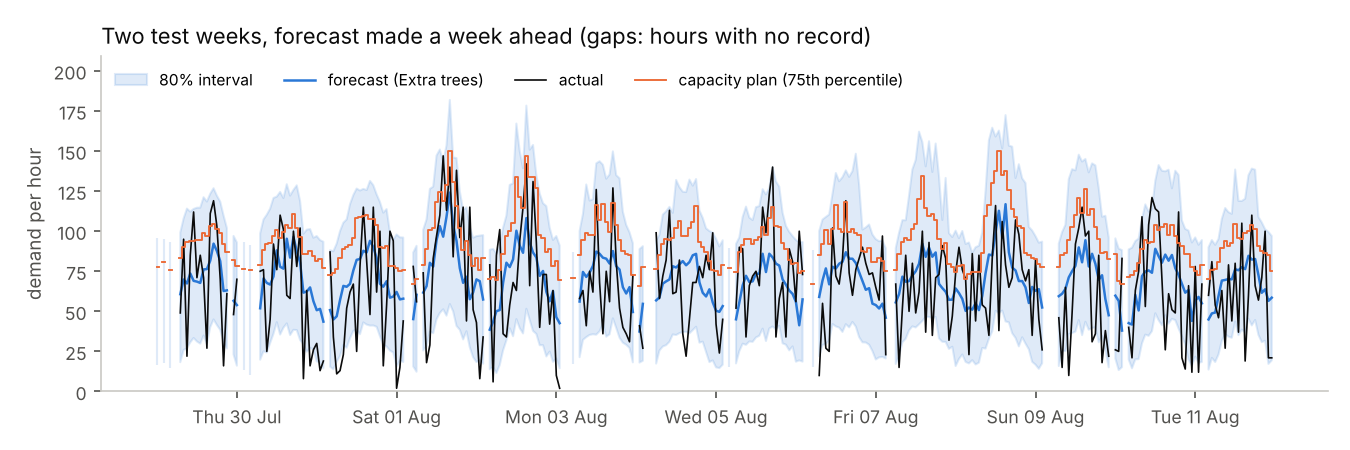

WAPE of the model by planning level: {'hour': '38.1%', '4-hour shift': '23.1%', 'day': '13.8%'}


In [14]:
t = load("hourly", "test")
display(pd.DataFrame(t["table"]).T[["mae", "wape", "mase", "bias"]].astype(float).round(3))
display(Image(filename=str(FIG / "hourly_test_weeks.png"), width=760))
ag = load("hourly", "aggregation")
print("WAPE of the model by planning level:", {k: f"{v[t['model']]['wape']:.1%}" for k, v in ag.items()})

In [15]:
dec = load("hourly", "decision")
d = pd.DataFrame(dec["plans"]).T
d["relative cost"] = d.cost / d.cost.iloc[0]
display(d[["relative cost", "service_level", "fill_rate", "idle_capacity_share"]].astype(float).round(3))
iv = load("hourly", "intervals")
print(f"80% interval coverage on the test period: {iv['quantile_boosting']['coverage']:.1%}")

,relative cost,service_level,fill_rate,idle_capacity_share
Model: 75th-percentile forecast,1.000,0.738,0.929,0.292
Seasonal naive (same hour last week) x 1.21 (buffer tuned on dev),1.625,0.613,0.809,0.328
"Hour-of-week mean, last 4 weeks x 1.30 (buffer tuned on dev)",1.239,0.678,0.882,0.303
Static hour-of-week profile x 1.33 (buffer tuned on dev),1.074,0.686,0.902,0.277
Empirical 75th percentile of each hour of week (dev),1.076,0.700,0.903,0.280
"Extra trees: point forecast, no buffer",1.363,0.471,0.785,0.174


80% interval coverage on the test period: 78.9%


**What Part C shows:** a week ahead, no model beats the hour-of-week profile on point accuracy by more than noise. The value is in planning under uncertainty: capacity set at the cost-optimal 75th percentile costs **7% less** than the best rule-of-thumb plan, and 38% less than "last week plus a buffer".

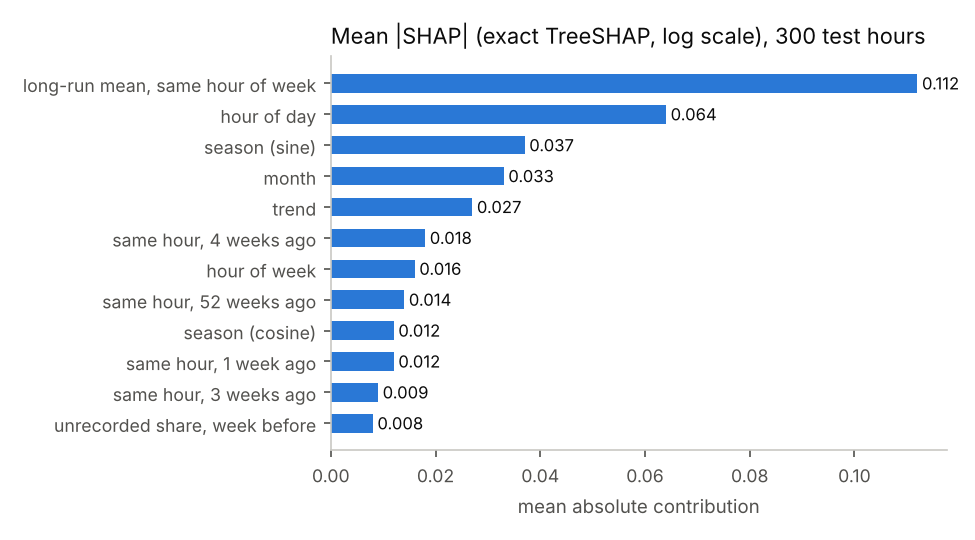

In [16]:
display(Image(filename=str(FIG / "hourly_shap.png"), width=600))

## Part A: TCS iON data → weekly ordering for 500 product × outlet series

My original project on this data used a random train/test split (the model saw the future), reused one category's results in the other categories' tables, and treated ID codes as numbers. Here it is rebuilt: time-ordered validation, intermittent-demand baselines, and an order-up-to decision. The data files are not redistributed; with them in `data/tcs/` the checks run live.

In [17]:
tcs_dir = ROOT / "data" / "tcs"
if all((tcs_dir / f"{f}.csv").exists() for f in ("train_data", "product_prices", "date_to_week_id_map")):
    from retail_demand.tcs import data as tdata, features as tfeat
    td = tdata.load(tcs_dir); tp = tdata.build_panel(td); tq = tdata.quality(td, tp)
    print(f"panel: {tp.sales.shape[0]} series x {tp.sales.shape[1]} days (live)")
else:
    tp = None; tq = load("tcs", "quality"); print("data not present: showing saved checks")
for k in ("validity", "uniqueness", "completeness", "consistency", "accuracy", "relevance"):
    print(f"\n{k.upper()}"); print(json.dumps({a: b for a, b in tq[k].items() if len(str(b)) < 200}, indent=1, default=str))

panel: 500 series x 790 days (live)

VALIDITY
{
 "rows": 395000,
 "negative_sales": 0,
 "non_integer_sales": 0,
 "non_positive_prices": 0,
 "price_min": 0.05,
 "price_max": 44.36,
 "null_values": {
  "train_data": 0,
  "product_prices": 0,
  "date_to_week_id_map": 0
 }
}

UNIQUENESS
{
 "duplicate_product_outlet_date": 0,
 "duplicate_price_rows": 0
}

COMPLETENESS
{
 "series": 500,
 "days": 790,
 "first_date": "2012-01-01",
 "last_date": "2014-02-28",
 "grid_cells": 395000,
 "rows": 395000,
 "sales_rows_without_price": 0,
 "zero_sales_share": 0.6243594936708861
}

CONSISTENCY
{
 "departments_per_product_max": 1,
 "categories_per_department_max": 1,
 "states_per_outlet_max": 1,
 "price_changes_share_of_weeks": 0.010457627118644067,
 "outlets_by_state": {
  "Kerala": [
   331,
   332,
   333
  ],
  "Maharashtra": [
   111,
   112,
   113,
   114
  ],
  "Telangana": [
   221,
   222,
   223
  ]
 }
}

ACCURACY
{
 "prices_below_half_series_median": 41,
 "prices_above_double_series_median": 3

**What the checks mean for modelling:** the grid is complete and valid, but 62% of product-outlet-days are zero and most series are *intermittent* or *lumpy* (Syntetos-Boylan classes), so methods built for intermittent demand (Croston, SBA, TSB) are the right baselines and RMSE in units (not MAPE) is the right metric. 72 series go more than 180 days without a sale, most likely not stocked; they are kept (zero is the correct forecast). Prices change in only about 1% of weeks, so price effects are weakly identified.

{'drinks_and_food': '65%', 'fast_moving_consumer_goods': '31%', 'others': '4%'} | weekend / weekday: 1.36
discount days: median log difference +0.095 over 176 series (Wilcoxon p = 2e-06)


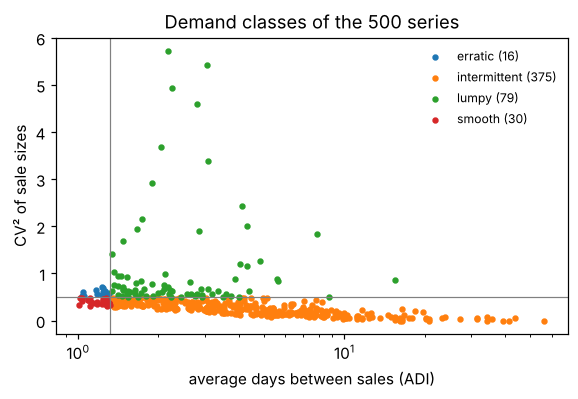

In [18]:
if tp is not None:
    cls = tdata.classify(tp.sales)
    fig, ax = plt.subplots(figsize=(6, 3.5))
    for k, g in cls.groupby("class"):
        ax.scatter(g.adi, g.cv2, s=10, label=f"{k} ({len(g)})")
    ax.axvline(1.32, color="grey", lw=0.8); ax.axhline(0.49, color="grey", lw=0.8)
    ax.set_xscale("log"); ax.set_xlabel("average days between sales (ADI)"); ax.set_ylabel("CV² of sale sizes"); ax.legend(frameon=False, fontsize=8)
    ax.set_title("Demand classes of the 500 series"); plt.show()
eda = load("tcs", "eda")
print({k: f"{v:.0%}" for k, v in eda["share_of_sales_by_category"].items()}, "| weekend / weekday:", round(eda["weekend_vs_weekday_ratio"], 2))
pe = eda["price_discount_effect_within_series"]
print(f"discount days: median log difference {pe['median_log_diff']:+.3f} over {pe['series_with_discount_days']} series (Wilcoxon p = {pe['wilcoxon_p']:.1g})")

**Features** at each weekly order date, for each of the next 7 days: recent levels (7-112 days), same-weekday mean, volatility, zero share, days since the last sale, average sale size and interval, the Croston / SBA / TSB estimates, product / department / outlet codes (categorical for linear models), and the week's planned selling price relative to the item's usual price. `tests/test_tcs.py` changes all sales after the order date and checks that no feature moves.

In [19]:
if tp is not None:
    paths = tfeat.intermittent_paths(tp.sales)
    rows = tfeat.origin_rows(tp, 600, paths)
    display(rows[tfeat.FEATURES + ["y"]].head(8).round(3))

,product_code,department_identifier,category_code,outlet,state_code,mean_7,mean_28,mean_56,mean_112,std_28,zero_share_28,zero_share_112,days_since_sale,size_112,interval_112,croston,sba,tsb,dow_mean_8,h,dow,dom,month,woy_sin,woy_cos,price,price_rel,price_change,price_rel_dept,y
0,0.0,11.0,2.0,111.0,1.0,0.714,0.571,0.518,0.554,1.015,0.679,0.670,2.0,1.676,3.027,0.558,0.530,0.486,0.625,1,5,24,8,-0.815,-0.58,3.43,1.0,0.0,0.631,1.0
1,1.0,11.0,2.0,111.0,1.0,2.714,1.857,1.607,2.054,1.529,0.250,0.241,0.0,2.706,1.318,2.057,1.954,2.134,2.375,1,5,24,8,-0.815,-0.58,7.78,1.0,0.0,1.431,5.0
2,2.0,12.0,2.0,111.0,1.0,0.429,0.214,0.107,0.089,0.773,0.929,0.964,2.0,2.500,28.000,0.142,0.135,0.156,0.000,1,5,24,8,-0.815,-0.58,0.97,1.0,0.0,0.327,0.0
3,3.0,12.0,2.0,111.0,1.0,0.000,0.214,0.143,0.161,0.558,0.857,0.866,16.0,1.200,7.467,0.174,0.165,0.064,0.000,1,5,24,8,-0.815,-0.58,4.97,1.0,0.0,1.673,0.0
4,4.0,21.0,1.0,111.0,1.0,1.143,1.214,1.143,1.054,1.206,0.286,0.402,1.0,1.761,1.672,1.304,1.239,1.215,1.125,1,5,24,8,-0.815,-0.58,4.88,1.0,0.0,1.229,2.0
5,5.0,21.0,1.0,111.0,1.0,1.857,2.571,2.821,2.732,1.699,0.107,0.107,0.0,3.060,1.120,2.390,2.270,2.400,3.375,1,5,24,8,-0.815,-0.58,2.84,1.0,0.0,0.715,4.0
6,6.0,21.0,1.0,111.0,1.0,2.000,1.500,1.696,1.562,1.376,0.286,0.286,0.0,2.188,1.400,1.814,1.724,1.888,2.000,1,5,24,8,-0.815,-0.58,6.97,1.0,0.0,1.756,2.0
7,7.0,21.0,1.0,111.0,1.0,1.000,0.643,0.464,0.589,0.972,0.607,0.598,0.0,1.467,2.489,0.575,0.546,0.717,0.375,1,5,24,8,-0.815,-0.58,3.97,1.0,0.0,1.000,1.0


,R² train (random split),R² test (random split),R² test (last 8 weeks)
drinks_and_food,1.0,0.480,0.072
fast_moving_consumer_goods,1.0,0.199,-0.056
others,1.0,0.050,-0.084


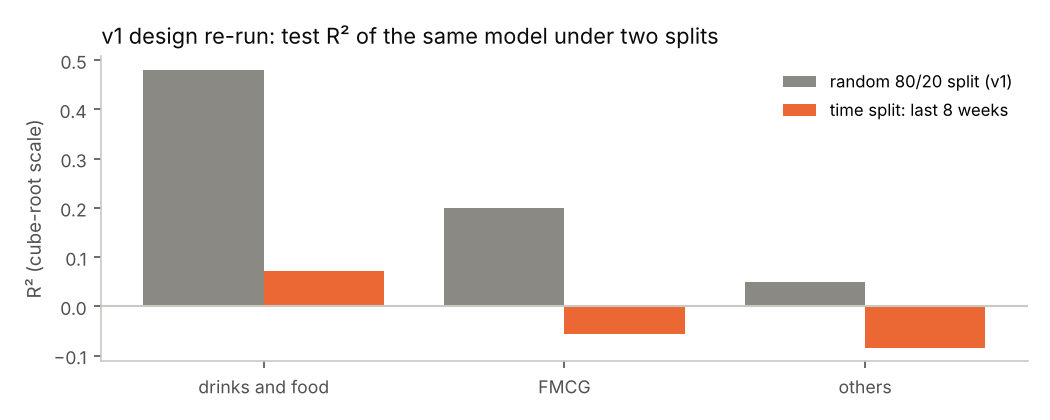

In [20]:
v1 = load("tcs", "v1")
display(pd.DataFrame({k: {"R² train (random split)": v["random_split"]["r2_train"], "R² test (random split)": v["random_split"]["r2_test"],
                          "R² test (last 8 weeks)": v["time_split_last_8_weeks"]["r2_test"]} for k, v in v1["categories"].items()}).T.round(3))
display(Image(filename=str(FIG / "tcs_v1_split.png"), width=640))

Re-running the original design shows the problem: the same model that scores R² 0.48 on a random split scores 0.07 when it must forecast the last 8 weeks, and negative for two categories.

,model,baseline,cv_rmse,cv_rmse_sd,cv_mae,cv_bias
0,Extra trees,False,2.710,0.452,0.951,0.011
1,Random forest,False,2.720,0.458,0.952,0.013
2,Gradient boosting (squared error),False,2.725,0.457,0.957,0.005
3,Neural network (MLP 64-32),False,2.735,0.438,0.948,-0.039
4,k-nearest neighbours (k=50),False,2.749,0.430,0.965,-0.025
5,Ridge,False,2.775,0.475,0.977,0.009
6,Gradient boosting (Poisson),False,2.799,0.478,0.952,-0.002
7,TSB,True,2.803,0.459,0.959,-0.027
8,Poisson GLM,False,2.819,0.482,0.998,0.023
9,SBA (Syntetos-Boylan),True,2.832,0.458,1.070,0.024


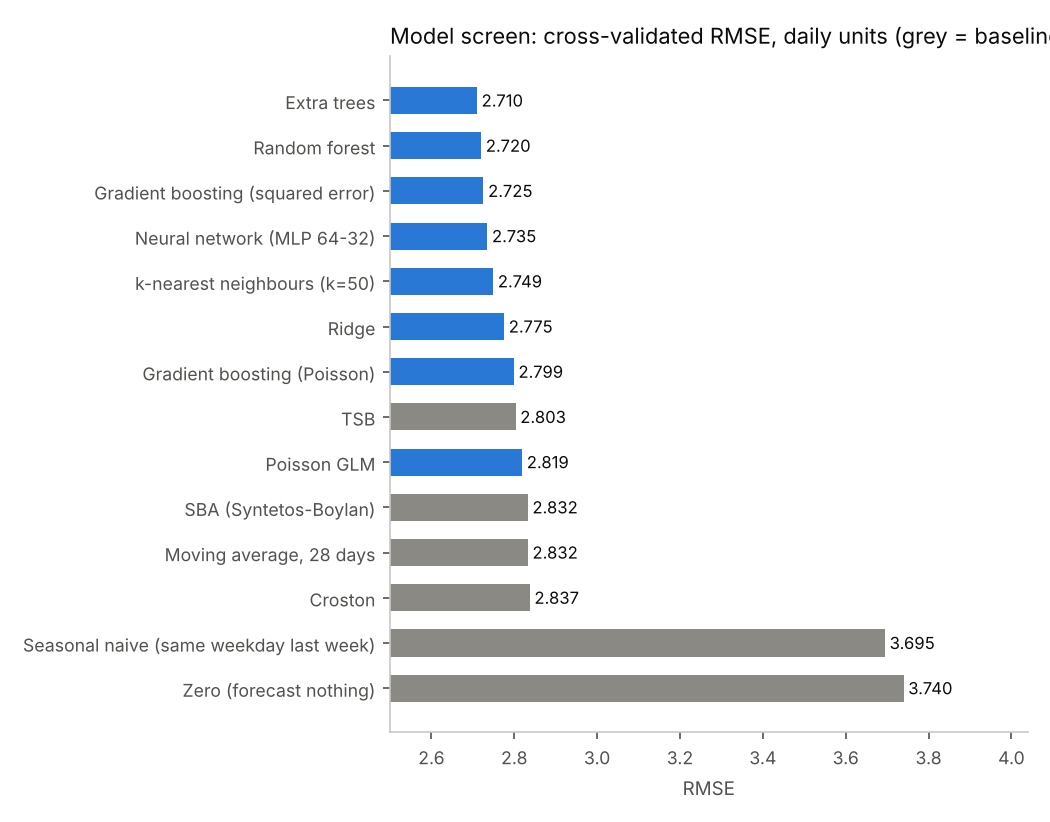

In [21]:
sc = load("tcs", "screen")
display(pd.DataFrame(sc["table"])[["model", "baseline", "cv_rmse", "cv_rmse_sd", "cv_mae", "cv_bias"]].round(3))
display(Image(filename=str(FIG / "tcs_screen.png"), width=640))

In [22]:
t = load("tcs", "test")
display(pd.DataFrame(t["table"]).T[["rmse", "mae", "wape", "bias"]].astype(float).round(3))
display(pd.DataFrame(t["rmse_by_demand_class"]).T.round(3))

,rmse,mae,wape,bias
Extra trees,3.317,0.964,0.822,-0.029
Zero (forecast nothing),4.400,1.173,1.000,-1.000
Seasonal naive (same weekday last week),4.526,1.195,1.019,0.025
"Moving average, 28 days",3.553,1.043,0.889,-0.003
Croston,3.547,1.138,0.970,0.082
SBA (Syntetos-Boylan),3.526,1.119,0.954,0.028
TSB,3.451,1.007,0.859,-0.010
Ridge,3.296,0.975,0.831,-0.051
Gradient boosting (Poisson),3.312,0.940,0.801,-0.080


,rows,share_of_sales,Extra trees,SBA (Syntetos-Boylan),"Moving average, 28 days"
erratic,784.0,0.085,3.353,3.570,3.581
intermittent,20776.0,0.347,0.919,1.002,0.954
lumpy,4704.0,0.374,7.527,7.962,8.065
smooth,1736.0,0.193,2.959,3.320,3.278


,wape_of_weekly_totals,fill_rate,stock_vs_demand,stock_vs_demand_at_95pct_fill_ex_post,stock_saving_vs_rule_ex_post
Extra trees: mean forecast x 7,0.437,0.944,1.917,2.047,0.066
SBA (Syntetos-Boylan) x 7,0.585,0.932,2.415,3.001,-0.369
Rule of thumb: 28-day average x 7,0.517,0.933,2.562,3.384,-0.543
Quantile gradient boosting of the 7-day total (q = 0.9),0.784,0.946,1.896,1.970,0.101
Rule of thumb: each item's 90th percentile of its last 26 weekly sales,0.900,0.973,3.304,2.192,0.000


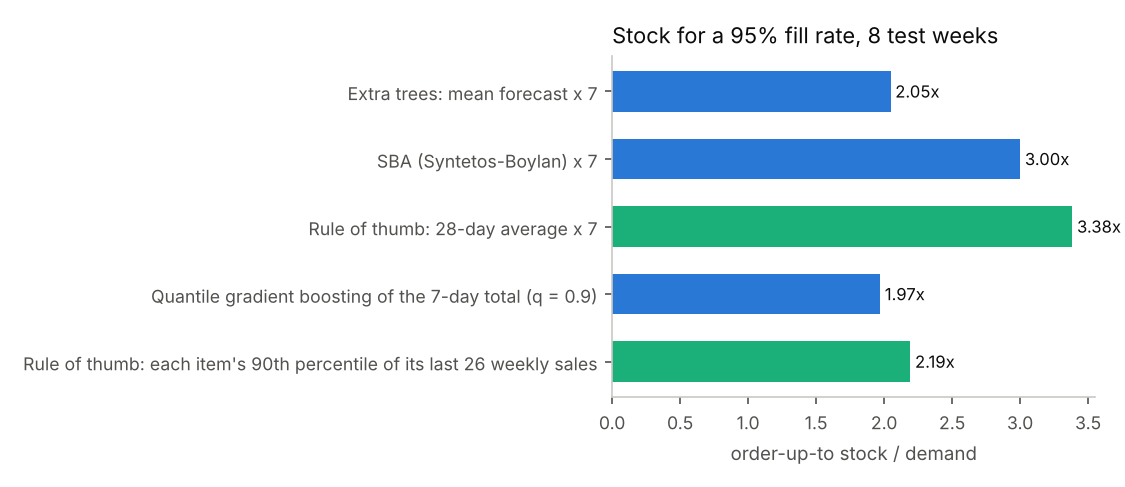

In [23]:
dec = load("tcs", "decision")
display(pd.DataFrame(dec["policies"]).T[["wape_of_weekly_totals", "fill_rate", "stock_vs_demand", "stock_vs_demand_at_95pct_fill_ex_post", "stock_saving_vs_rule_ex_post"]].astype(float).round(3))
display(Image(filename=str(FIG / "tcs_decision.png"), width=700))

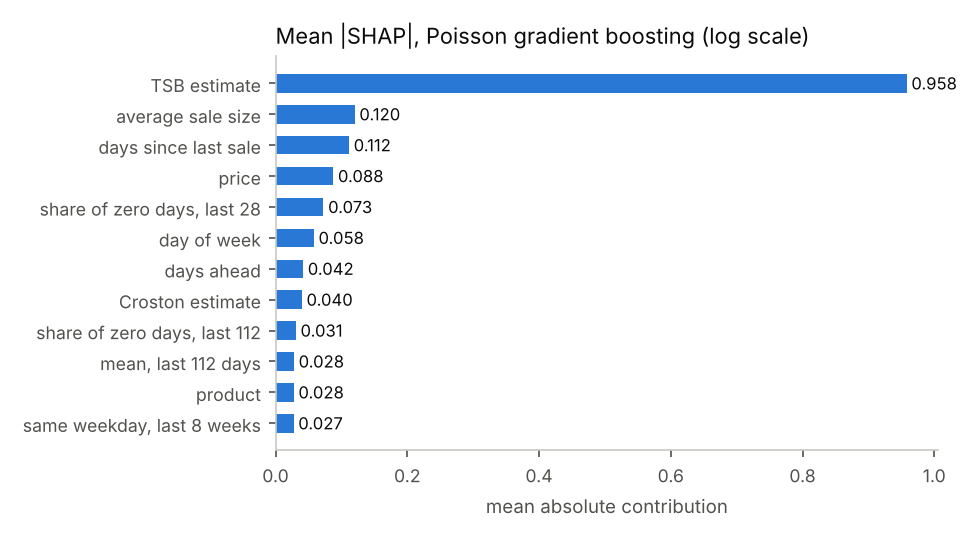

,id,hypothesis,evidence,p_holm,verdict
0,H1,The model has lower error than Seasonal naive (same weekday last week) on most series,"Seasonal naive (same weekday last week) worse on 90% of series; RMSE 3.317 vs 4.526 (difference +1.209, CI +0.885 to +1.560)",3.603537e-78,supported
1,H2,"The model has lower error than Moving average, 28 days on most series","Moving average, 28 days worse on 67% of series; RMSE 3.317 vs 3.553 (difference +0.236, CI +0.157 to +0.322)",2.290436e-28,supported
2,H3,The model has lower error than SBA (Syntetos-Boylan) on most series,"SBA (Syntetos-Boylan) worse on 73% of series; RMSE 3.317 vs 3.526 (difference +0.209, CI +0.165 to +0.284)",6.010775e-40,supported
3,H4,The model has lower error than Croston on most series,"Croston worse on 72% of series; RMSE 3.317 vs 3.547 (difference +0.230, CI +0.177 to +0.311)",4.183407e-38,supported
4,H5,Sales are higher when an item is discounted (price < 95% of its usual price),median log difference +0.095 over 176 series,3.706587e-06,supported
5,H6,Ordering from the quantile model needs less stock than the per-item 90th-percentile rule for a 95% fill rate,saving +10.1% (series bootstrap CI +6.0% to +16.7%),2.000000e-03,supported


In [24]:
display(Image(filename=str(FIG / "tcs_shap.png"), width=620))
display(pd.DataFrame(load("tcs", "hypotheses"))[["id", "hypothesis", "evidence", "p_holm", "verdict"]])

## Classical time-series models: ARIMA, SARIMA, Holt-Winters and Prophet

Do the statistical models a planner would reach for first match the machine-learning models? Each family is run under the same information rules as the ML models (Part C: every forecast for hour *t* uses data up to *t* − 168 h only; Part B: data up to the order date), with two specifications per family compared on validation data and the better one evaluated once on the test period. Code: `src/retail_demand/classical.py`; tests in `tests/test_classical.py` check that each week-ahead forecast equals the model's own forecast and ignores the last 167 hours.

In [25]:
ch = load("hourly", "classical")
tab = pd.DataFrame({k: {"MAE": v["mae"], "95% CI": f"{v['mae_ci'][0]:.1f}-{v['mae_ci'][1]:.1f}", "WAPE": v["wape"],
                        "MAE vs ML (bootstrap CI)": (f"{v['mae_diff_vs_ml_ci']['value']:+.2f} ({v['mae_diff_vs_ml_ci']['ci'][0]:+.2f} to {v['mae_diff_vs_ml_ci']['ci'][1]:+.2f})"
                                                     if "mae_diff_vs_ml_ci" in v else "reference"),
                        "DM p vs ML (Holm)": v.get("dm_vs_ml", {}).get("p_holm", np.nan)} for k, v in ch["table"].items()}).T
display(tab.sort_values("MAE"))
for fam, r in ch["families"].items():
    print(f"{fam:13s} validation MAE by specification:", {k: round(v["validation_mae"], 2) for k, v in r["specs"].items()}, "->", r["chosen"])
display(pd.DataFrame(ch["decision"]).T[["relative_cost"]].round(3))

,MAE,95% CI,WAPE,MAE vs ML (bootstrap CI),DM p vs ML (Holm)
Extra trees,29.268915,28.0-31.0,0.381099,reference,NaN
Static hour-of-week profile,30.106119,28.1-33.6,0.392,+0.84 (-0.27 to +2.66),NaN
"SARIMA(1,0,1)(1,0,1)24 + weekly Fourier",30.111531,28.1-33.6,0.39207,+0.84 (-0.19 to +2.65),0.335636
"Prophet, additive seasonality",30.305262,28.7-32.8,0.394593,+1.04 (+0.22 to +2.12),0.139924
"ARIMA(2,0,1) + weekly Fourier",30.352713,28.2-33.9,0.395211,+1.08 (+0.02 to +2.94),0.335636
"Holt-Winters, additive season 168, damped trend",31.483948,29.2-34.8,0.40994,+2.22 (+0.52 to +4.44),0.139924


ARIMA         validation MAE by specification: {'ARIMA(2,0,1) + weekly Fourier': 30.53, 'ARIMA(2,1,1) + weekly Fourier': 30.67} -> ARIMA(2,0,1) + weekly Fourier
SARIMA        validation MAE by specification: {'SARIMA(1,0,1)(1,0,1)24 + weekly Fourier': 30.4, 'SARIMA(2,0,0)(2,0,0)24 + weekly Fourier': 30.56} -> SARIMA(1,0,1)(1,0,1)24 + weekly Fourier
Holt-Winters  validation MAE by specification: {'Holt-Winters, additive season 168, no trend': 31.54, 'Holt-Winters, additive season 168, damped trend': 31.53} -> Holt-Winters, additive season 168, damped trend
Prophet       validation MAE by specification: {'Prophet, additive seasonality': 31.14, 'Prophet, multiplicative seasonality': 31.72} -> Prophet, additive seasonality


,relative_cost
"Quantile gradient boosting, 75th percentile (Part C model)",1.0
"ARIMA(2,0,1) + weekly Fourier x 1.49",1.07006
"SARIMA(1,0,1)(1,0,1)24 + weekly Fourier x 1.47",1.056738
"Holt-Winters, additive season 168, damped trend x 1.33",1.159011
"Prophet, additive seasonality x 1.26",1.089832


,WAPE,RMSLE,"WAPE vs ML, points (store bootstrap CI)",series where worse than ML
Ridge (log scale),0.161318,0.491963,-0.2 (-0.9 to +0.8),0.601307
Random forest (log scale),0.162867,0.446574,reference,NaN
"SARIMA(1,0,1)(0,1,1)7",0.170953,0.479613,+0.8 (-0.1 to +2.0),0.550802
"Holt-Winters (ETS A,N,A), weekly",0.172325,0.48237,+0.9 (+0.2 to +1.8),0.554961
"Same-weekday mean, last 4 weeks",0.175989,0.53113,+1.3 (+0.6 to +2.1),0.695781
"Prophet, weekly + holidays + promotions",0.180311,0.453298,+1.7 (-0.3 to +4.9),0.588235
"ARIMA(2,1,2)",0.20535,0.505155,+4.2 (+3.4 to +5.1),0.705288
"Seasonal naive (same weekday, last week)",0.206651,0.61704,+4.4 (+3.0 to +6.0),0.809269


Holt-Winters  validation WAPE by specification: {'Holt-Winters (ETS A,N,A), weekly': 0.131, 'Holt-Winters (ETS A,Ad,A), weekly': 0.1324} -> Holt-Winters (ETS A,N,A), weekly
Prophet       validation WAPE by specification: {'Prophet, weekly + yearly + holidays + promotions': 0.2181, 'Prophet, weekly + holidays + promotions': 0.2029} -> Prophet, weekly + holidays + promotions
ARIMA         validation WAPE by specification: {'ARIMA(1,1,1)': 0.2131, 'ARIMA(2,1,2)': 0.2119} -> ARIMA(2,1,2)
SARIMA        validation WAPE by specification: {'SARIMA(1,0,1)(0,1,1)7': 0.1274, 'SARIMA(1,1,1)(0,1,1)7': 0.1387, 'SARIMAX(1,0,1)(0,1,1)7 + promotions, national holidays': 0.1372} -> SARIMA(1,0,1)(0,1,1)7


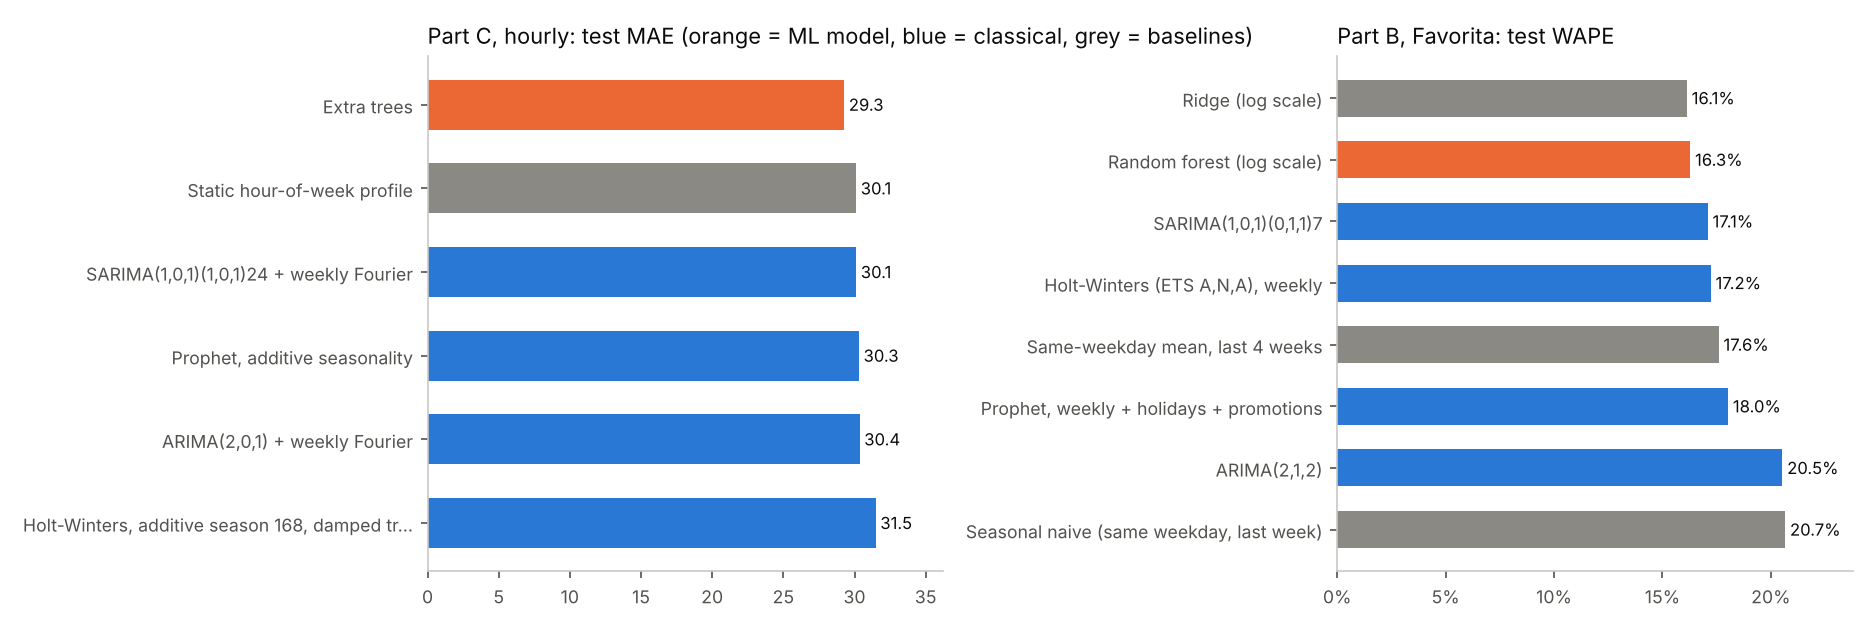

In [26]:
cf = load("favorita", "classical")
tab = pd.DataFrame({k: {"WAPE": v["wape"], "RMSLE": v["rmsle"],
                        "WAPE vs ML, points (store bootstrap CI)": (f"{100*v['wape_diff_vs_ml_store_bootstrap']['value']:+.1f} "
                                                                    f"({100*v['wape_diff_vs_ml_store_bootstrap']['ci'][0]:+.1f} to {100*v['wape_diff_vs_ml_store_bootstrap']['ci'][1]:+.1f})")
                        if "wape_diff_vs_ml_store_bootstrap" in v else "reference",
                        "series where worse than ML": v.get("paired_series_test_vs_ml", {}).get("series_where_a_worse", np.nan)}
                    for k, v in cf["table"].items()}).T
display(tab.sort_values("WAPE"))
for fam, r in cf["families"].items():
    print(f"{fam:13s} validation WAPE by specification:", {k: round(v["validation_wape_sample"], 4) for k, v in r["specs"].items()}, "->", r["chosen"])
display(Image(filename=str(FIG / "classical_benchmark.png"), width=900))

**What the classical benchmark shows:** well-specified seasonal models (SARIMA, Holt-Winters) come within about one point of the ML models on point accuracy, and the SARIMA gap is not statistically significant on either dataset; ARIMA without seasonal terms is no better than last week's sales. Prophet was beaten by SARIMA on both datasets. Where the ML approach clearly wins is the decision: point forecasts plus a tuned buffer cost 5-14% more than the quantile model's staffing plan, with every confidence interval above zero. SARIMA or Holt-Winters is a credible, cheaper fallback for point forecasts; the capacity plan should come from the quantile model.